# 02 · Exploratory Data Analysis

**Goal:** understand the target (`price`), find which features relate to it, and spot what needs cleaning,
transforming, binning, encoding or dropping before modeling.

The notebook answers the six Lightning Talk EDA questions (sections 2–7), then adds checks that matter for
this dataset. Only tools from the course are used: pandas, numpy, matplotlib and seaborn.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('../src')
from clean import load_raw, clean, PRICE_MIN, PRICE_MAX

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', None)

## 1. Cleaning: why each fixed rule is needed

`01_data_overview.ipynb` found placeholder prices, impossible odometers, empty rows and reposted cars.
The cells below show the numbers behind each rule in `src/clean.py`. None of these rules learns from the data,
so they are safe before the train/test split.

In [2]:
raw = load_raw()
print(f'Raw file: {len(raw):,} rows')

price_bins = pd.cut(raw['price'], [-1, 0, 499, 999, 150_000, 1e12],
                    labels=['0', '1-499', '500-999', '1,000-150,000', '> 150,000'])
raw['price'].groupby(price_bins, observed=True).size().to_frame('rows')

Raw file: 426,880 rows


,rows
price,
0,32895
1-499,9199
500-999,4221
"1,000-150,000",380369
"> 150,000",196


**Price $1,000–$150,000.** Below $1,000 are "call for price" placeholders (0 alone is 7.7% of the file) and
down-payment adverts. Above $150,000 there are only 196 listings, most of them typos (a few billion dollars).

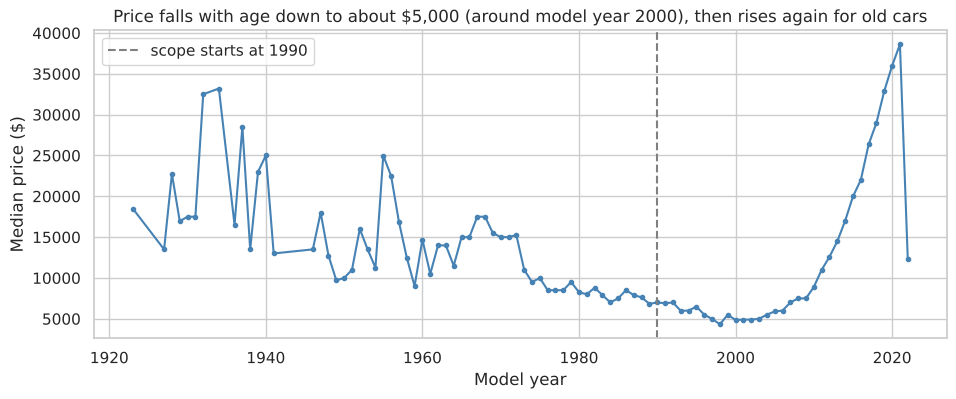

In [3]:
# Price vs model year on the raw prices in range: why the scope starts at 1990
in_range = raw[raw['price'].between(PRICE_MIN, PRICE_MAX) & raw['year'].notna()]
by_year = in_range.groupby('year')['price'].agg(['count', 'median'])
by_year = by_year[by_year['count'] >= 30]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(by_year.index, by_year['median'], marker='.', color='steelblue')
ax.axvline(1990, color='grey', ls='--', label='scope starts at 1990')
ax.set_xlabel('Model year')
ax.set_ylabel('Median price ($)')
ax.set_title('Price falls with age down to about $5,000 (around model year 2000), then rises again for old cars')
ax.legend()
plt.show()

For everyday cars the median price falls with age until it bottoms out at about \$5,000 around model year 2000,
stays low through the 1990s, and then turns noisy and rises: before about 1990 the listings are classic and collector
cars, priced by rarity rather than age or mileage. The course advice is to model a separate segment only if justified;
since these are only 4.5% of the cleaned listings, this project keeps **model years 1990 and later**.
(The drop at model year 2022 rests on very few listings and is probably mistyped years.)

In [4]:
df = clean(raw)
print('\nClean data:', df.shape)

                                         step  rows_left  removed  share_of_raw_%
                                     raw file     426880        0           100.0
drop empty listings (all core fields missing)     426812       68           100.0
                 drop reposts of the same car     268554   158258            62.9
                   keep price $1,000-$150,000     239716    28838            56.2
                drop missing year or odometer     237423     2293            55.6
               keep odometer <= 500,000 miles     236444      979            55.4
                      keep model year >= 1990     225703    10741            52.9

Clean data: (225703, 19)


Reposts are the biggest step: **158,258 rows (37%)** were copies of a car already in the file. After all rules,
**225,703 listings** remain (52.9% of the raw file), which is still far above the 15k-row requirement.

## 2. What is the target column and what does it represent?

**`price`**: the asking price of the used car in US dollars, set by the seller (dealer or private).
Predicting it answers the question a buyer or seller asks first: *what is this car worth?*

## 3. Is the target categorical or continuous? Is it balanced?

count    225703.0
mean      16334.0
std       14063.0
min        1000.0
25%        6495.0
50%       11999.0
75%       21995.0
max      150000.0
Name: price, dtype: float64
skew: 2.07 | skew of log(price): -0.22


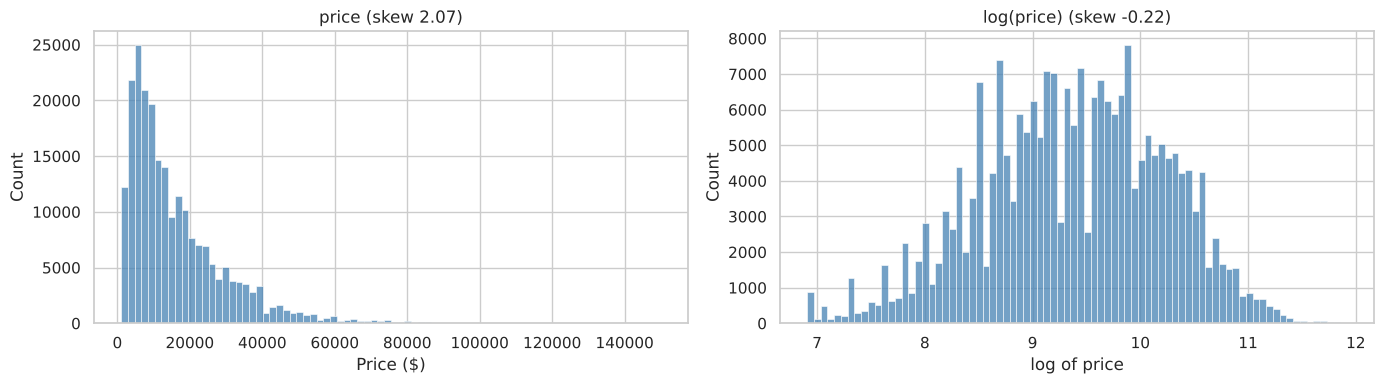

In [5]:
print(df['price'].describe().round(0))
print('skew:', round(df['price'].skew(), 2), '| skew of log(price):', round(np.log(df['price']).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['price'], bins=80, ax=axes[0], color='steelblue')
axes[0].set_title(f"price (skew {df['price'].skew():.2f})")
axes[0].set_xlabel('Price ($)')
sns.histplot(np.log(df['price']), bins=80, ax=axes[1], color='steelblue')
axes[1].set_title(f"log(price) (skew {np.log(df['price']).skew():.2f})")
axes[1].set_xlabel('log of price')
plt.tight_layout()
plt.show()

**Continuous → regression.** "Balanced" applies to classes, so for a continuous target we look at its shape:
`price` is **right-skewed** (median \$11,999, mean \$16,334, skew 2.07). A log transform makes it nearly
symmetric (skew −0.22), so models will be compared on both `price` and `log(price)` (lesson 06), with errors
reported back in dollars.

In [6]:
# Common price endings: sellers pick round or "charm" prices
endings = (df['price'] % 1000).value_counts().head(5)
print('Most common last three digits:', endings.to_dict())
print('Most common prices:', df['price'].value_counts().head(5).to_dict())

Most common last three digits: {995: 35018, 500: 27206, 0: 22094, 900: 17641, 999: 16633}
Most common prices: {4500: 2288, 6995: 2270, 3500: 2185, 7995: 2181, 5500: 2098}


## 4. What types of features do you have? How many of each?

In [7]:
target = 'price'
num_cols = ['year', 'car_age', 'odometer', 'lat', 'long']
cat_cols = ['manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission',
            'drive', 'size', 'type', 'paint_color', 'region', 'state']

summary = pd.DataFrame({
    'kind': ['numeric'] * len(num_cols) + ['categorical'] * len(cat_cols),
    'levels': [np.nan] * len(num_cols) + [df[c].nunique() for c in cat_cols],
}, index=num_cols + cat_cols)
print(summary['kind'].value_counts().to_string())
summary

kind
categorical    13
numeric         5


,kind,levels
year,numeric,NaN
car_age,numeric,NaN
odometer,numeric,NaN
lat,numeric,NaN
long,numeric,NaN
manufacturer,categorical,41.0
model,categorical,24166.0
condition,categorical,6.0
cylinders,categorical,8.0
fuel,categorical,5.0


- **5 numeric**: `year`, `car_age` (= 2021 − year, the same information), `odometer`, `lat`, `long`.
- **13 categorical**:
  - **ordinal** (have an order): `condition` (salvage → new), `cylinders` (3 → 12), `size` (sub-compact → full-size);
  - **nominal, low cardinality** (3–13 levels): `fuel`, `title_status`, `transmission`, `drive`, `type`, `paint_color`;
  - **high cardinality**: `manufacturer` (41), `state` (51), `region` (404), `model` (≈24,000 free-text spellings).

## 5. How many null values does each feature have?

In [8]:
miss = df[num_cols + cat_cols].isna().mean().mul(100).round(1).to_frame('null_%')
miss = miss[miss['null_%'] > 0].sort_values('null_%', ascending=False)
miss['median_price_when_missing'] = [df.loc[df[c].isna(), 'price'].median() for c in miss.index]
miss['median_price_when_filled'] = [df.loc[df[c].notna(), 'price'].median() for c in miss.index]
miss

,null_%,median_price_when_missing,median_price_when_filled
size,64.2,13499.0,9995.0
condition,39.7,14998.0,10000.0
cylinders,36.2,14790.0,10991.0
paint_color,29.8,10999.0,12500.0
drive,28.7,10900.0,12695.0
type,26.7,9990.0,12989.0
manufacturer,3.3,10500.0,11999.0
title_status,1.4,14500.0,11995.0
lat,1.3,19640.0,11995.0
long,1.3,19640.0,11995.0


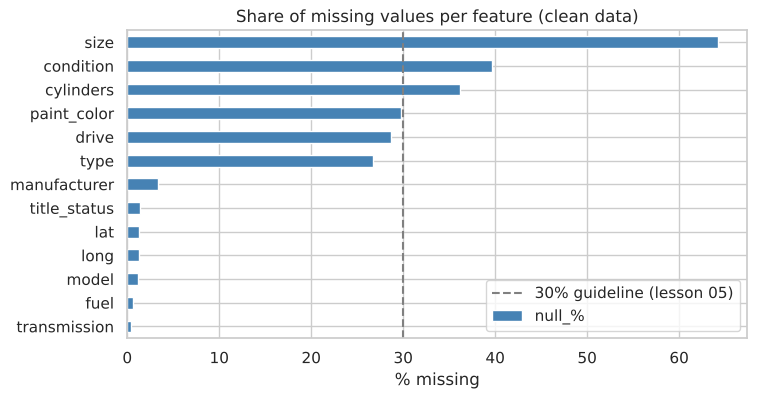

In [9]:
miss['null_%'].plot(kind='barh', figsize=(8, 4), color='steelblue')
plt.axvline(30, color='grey', ls='--', label='30% guideline (lesson 05)')
plt.gca().invert_yaxis()
plt.title('Share of missing values per feature (clean data)')
plt.xlabel('% missing')
plt.legend()
plt.show()

- `size` is **64.2%** missing → **drop** (above the course's ~30% guideline, and its signal is weak; see section 6).
- `condition` (39.7%), `cylinders` (36.2%), `paint_color` (29.8%), `drive` (28.7%) and `type` (26.7%) are too many
  rows to drop. Their missingness is **informative**: listings with no `condition` have a median price of
  \$14,998 vs \$10,000 when it is filled. Many dealers leave the field empty. Following lesson 05, they get their
  own **"unknown"** category instead of the most frequent value.
- `manufacturer` (3.3%), `title_status`, `lat`/`long`, `model` and `fuel` are under 2–4% missing → fill the
  category with "unknown" or the most frequent value inside the pipeline.

## 6. Which features are most correlated with the target, and with each other?

### 6a. Numeric features

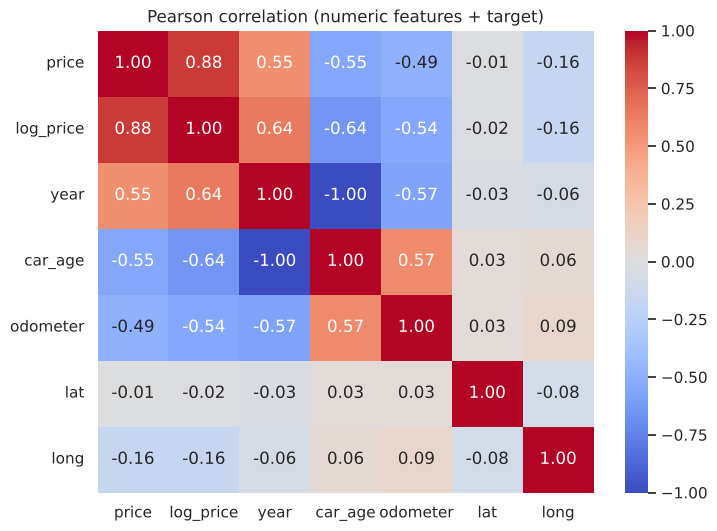

In [10]:
df['log_price'] = np.log(df['price'])
corr = df[['price', 'log_price', 'year', 'car_age', 'odometer', 'lat', 'long']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pearson correlation (numeric features + target)')
plt.show()

In [11]:
target_corr = pd.DataFrame({
    'pearson_price': df[num_cols].corrwith(df['price']),
    'pearson_log_price': df[num_cols].corrwith(df['log_price']),
    'spearman_price': df[num_cols].corrwith(df['price'], method='spearman'),
}).round(3).sort_values('spearman_price', key=abs, ascending=False)
target_corr

,pearson_price,pearson_log_price,spearman_price
year,0.550,0.645,0.699
car_age,-0.550,-0.645,-0.699
odometer,-0.492,-0.543,-0.589
long,-0.161,-0.159,-0.165
lat,-0.011,-0.018,-0.039


- **`car_age` / `year` is the strongest numeric driver** (Spearman 0.70), then **`odometer`** (−0.59).
  Spearman is higher than Pearson because the relationship is curved: prices fall fast in the first years, then slowly.
- `year` and `car_age` are the same information (correlation −1) → keep one (`car_age`).
- `car_age` and `odometer` correlate at 0.65 (Spearman) / 0.57 (Pearson): related but below 0.8, so both stay;
  Ridge regression (lesson 12) can handle the overlap.
- `lat` and `long` relate only weakly to price (|r| ≤ 0.17) on their own; location is better captured by `state`.

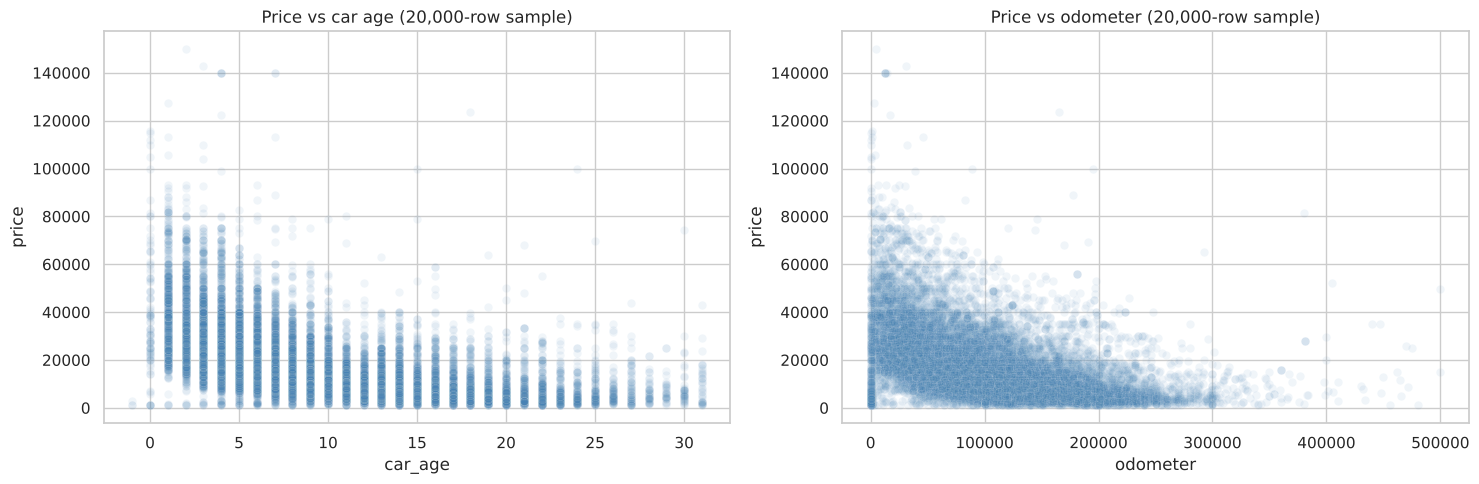

In [12]:
sample = df.sample(20_000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=sample, x='car_age', y='price', alpha=0.08, ax=axes[0], color='steelblue')
axes[0].set_title('Price vs car age (20,000-row sample)')
sns.scatterplot(data=sample, x='odometer', y='price', alpha=0.08, ax=axes[1], color='steelblue')
axes[1].set_title('Price vs odometer (20,000-row sample)')
plt.tight_layout()
plt.show()

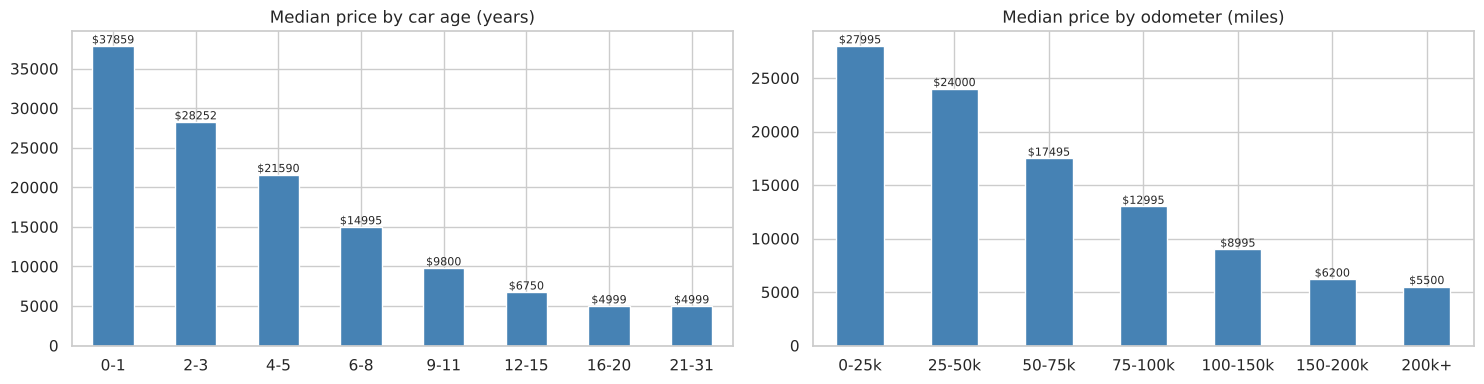

car_age      0-1      2-3      4-5      6-8     9-11    12-15    16-20  \
count     7479.0  23880.0  28314.0  47568.0  36640.0  40522.0  28145.0   
median   37859.0  28252.0  21590.0  14995.0   9800.0   6750.0   4999.0   

car_age    21-31  
count    13155.0  
median    4999.0  


In [13]:
age_bins = pd.cut(df['car_age'], [-2, 1, 3, 5, 8, 11, 15, 20, 31],
                  labels=['0-1', '2-3', '4-5', '6-8', '9-11', '12-15', '16-20', '21-31'])
odo_bins = pd.cut(df['odometer'], [-1, 25_000, 50_000, 75_000, 100_000, 150_000, 200_000, 500_000],
                  labels=['0-25k', '25-50k', '50-75k', '75-100k', '100-150k', '150-200k', '200k+'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, (name, b) in zip(axes, {'car age (years)': age_bins, 'odometer (miles)': odo_bins}.items()):
    med = df.groupby(b, observed=True)['price'].median()
    med.plot(kind='bar', ax=ax, color='steelblue')
    ax.bar_label(ax.containers[0], fmt='$%.0f', fontsize=8)
    ax.set_title(f'Median price by {name}')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()
print(df.groupby(age_bins, observed=True)['price'].agg(['count', 'median']).T)

A car loses value fastest when young: the median falls from **\$37,859** (0–1 years) to **\$14,995** (6–8 years),
then flattens at about **\$5,000** after 15 years. By mileage it falls from **\$27,995** (under 25k miles) to
**\$5,500** (200k+). This curve is why `log(price)` fits a straight line better than `price`.

### 6b. Categorical features

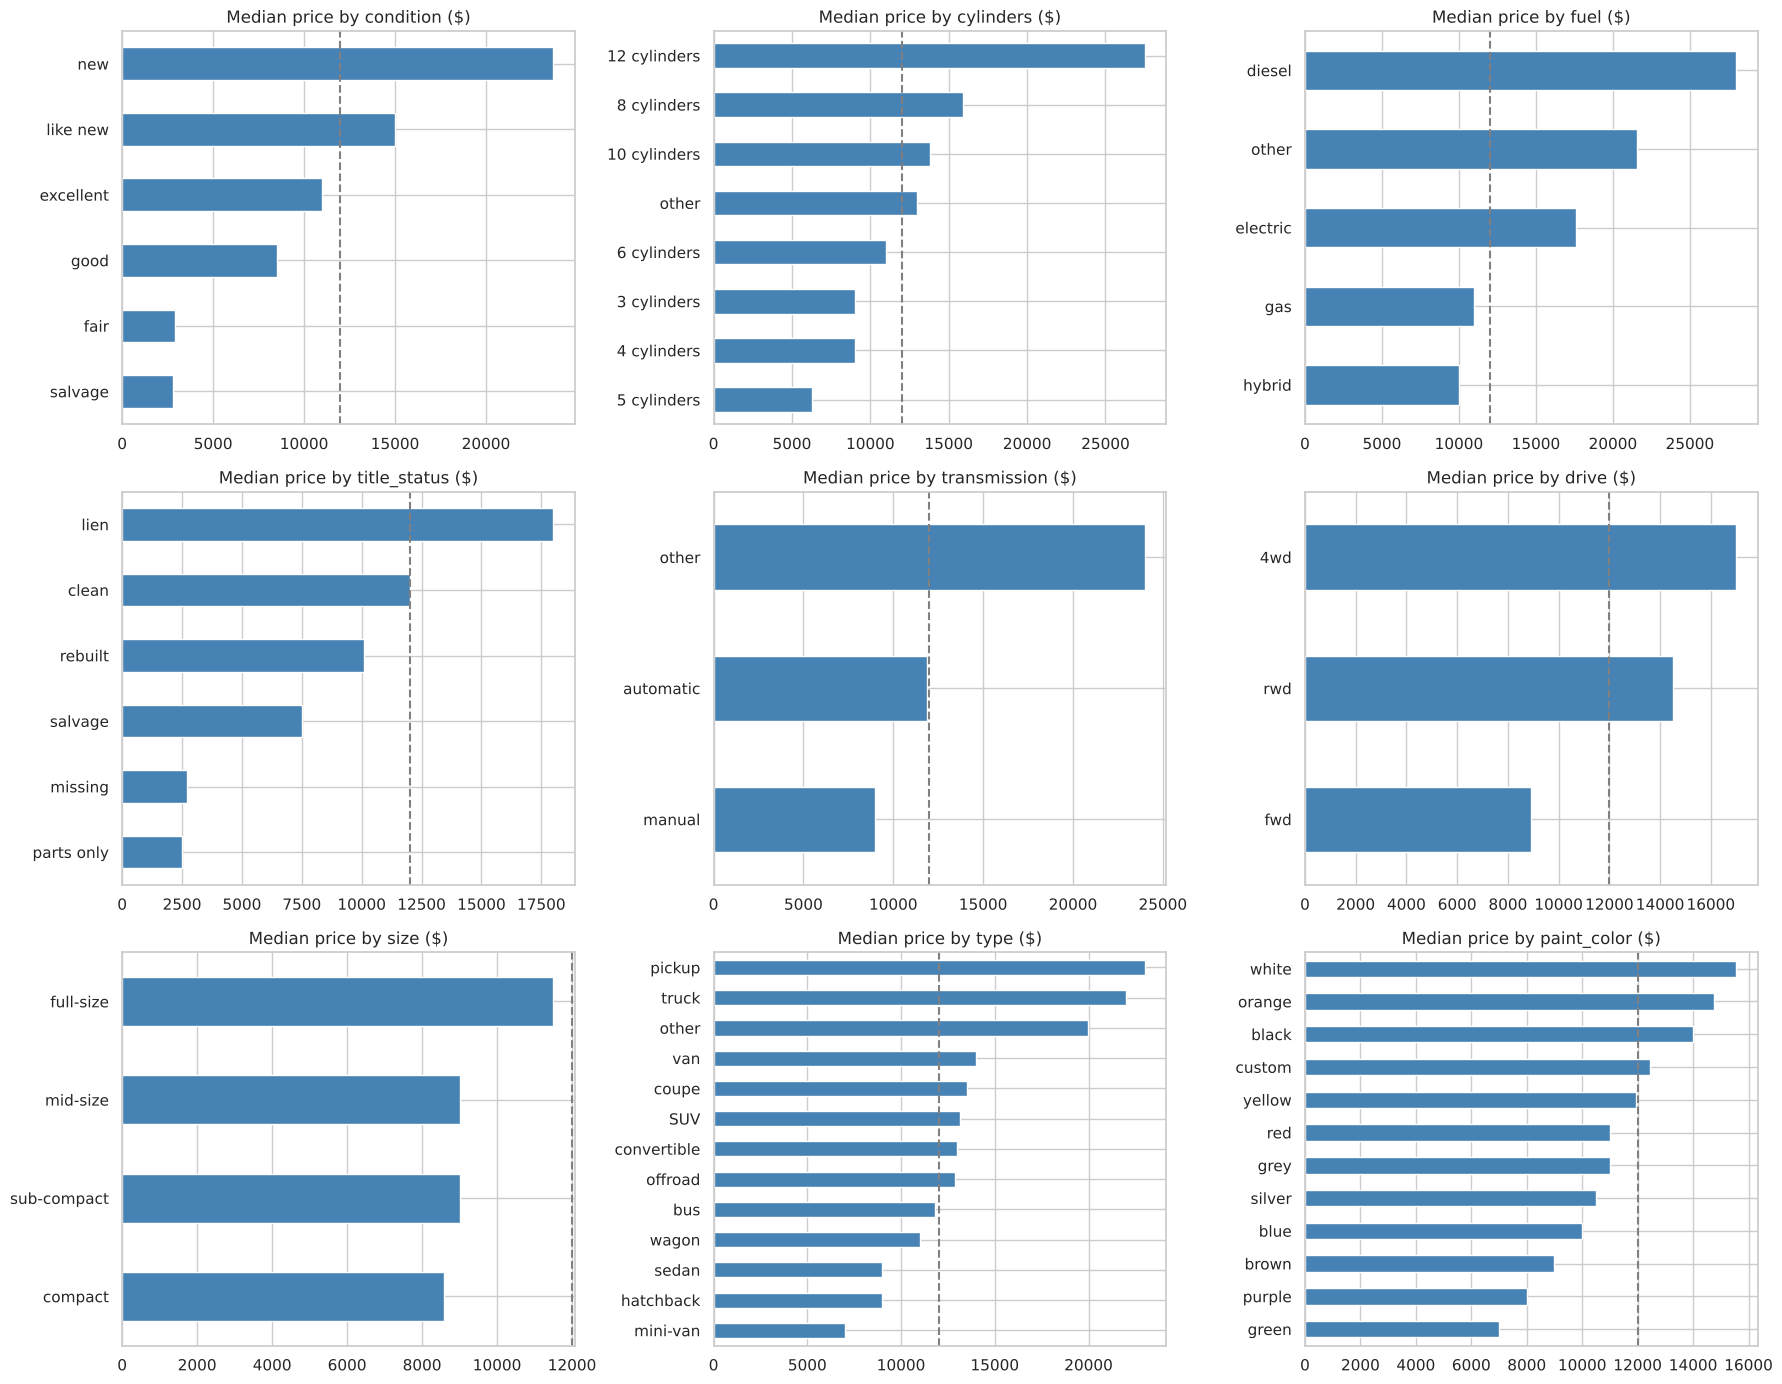

In [14]:
small_cats = ['condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color']
overall_median = df['price'].median()

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flat, small_cats):
    med = df.groupby(col)['price'].median().sort_values()
    med.plot(kind='barh', ax=ax, color='steelblue')
    ax.axvline(overall_median, color='grey', ls='--')
    ax.set_title(f'Median price by {col} ($)')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [15]:
rows = []
for col in small_cats + ['manufacturer', 'state']:
    counts = df[col].value_counts()
    med = df[df[col].isin(counts[counts >= 100].index)].groupby(col)['price'].median()  # levels with 100+ rows
    rows.append({'feature': col, 'levels': df[col].nunique(),
                 'lowest_median': med.min(), 'lowest_level': med.idxmin(),
                 'highest_median': med.max(), 'highest_level': med.idxmax(),
                 'spread_$': med.max() - med.min()})
spread = pd.DataFrame(rows).sort_values('spread_$', ascending=False).reset_index(drop=True)
spread

,feature,levels,lowest_median,lowest_level,highest_median,highest_level,spread_$
0,manufacturer,41,3995.0,saturn,41900.0,tesla,37905.0
1,cylinders,8,6300.0,5 cylinders,27500.0,12 cylinders,21200.0
2,condition,6,2800.0,salvage,23700.0,new,20900.0
3,fuel,5,9995.0,hybrid,27999.0,diesel,18004.0
4,type,13,6999.0,mini-van,22995.0,pickup,15996.0
5,title_status,6,2700.5,missing,18000.0,lien,15299.5
6,state,51,7300.0,de,22500.0,ak,15200.0
7,transmission,3,8999.0,manual,23990.0,other,14991.0
8,paint_color,12,6995.0,green,15550.0,white,8555.0
9,drive,3,8900.0,fwd,16995.0,4wd,8095.0


The **spread** (highest minus lowest median price across a column's categories, counting only levels with
100+ listings) ranks how strongly each categorical feature separates cheap from expensive cars.
The course does not teach Cramér's V or ANOVA, so this table replaces them.

- **`manufacturer`** has the widest spread, from budget and discontinued makes up to Tesla and Porsche.
- **`condition`** follows its order: salvage/fair ≈ \$2,800–2,900 → good \$8,500 → excellent \$11,000 → like new \$14,995 → new \$23,700 → **ordinal encoding**.
- **`fuel`**: diesel (\$27,999) is far above gas (\$10,995); diesel is mostly heavy pickups.
- **`type`**: pickups and trucks (\$22–23k) vs sedans and hatchbacks (\$9k).
- **`cylinders`** rises with engine size: 4 → \$8,995, 6 → \$10,995, 8 → \$15,900 → ordinal (number of cylinders).
- **`title_status`**: salvage, missing and parts-only titles are much cheaper.
- `size`, `drive` and `paint_color` have the smallest spreads; `size` is also 64% missing → drop it. `drive` stays (4wd vs fwd is a real difference); `paint_color` is a weak candidate.

In [16]:
# "other" levels are not small: who uses them?
for col in ['fuel', 'transmission']:
    print(df.groupby(col)['price'].agg(['count', 'median']).round(0), '\n')

           count   median
fuel                     
diesel     15053  27999.0
electric     779  17590.0
gas       198237  10995.0
hybrid      3007   9995.0
other       7362  21592.0 

               count   median
transmission                 
automatic     200293  11900.0
manual         13977   8999.0
other          10605  23990.0 



`transmission = other` (10,605 rows, median \$23,990) and `fuel = other` (7,362 rows, median \$21,593) are priced
far above the common levels. They are likely dealer listings that use their own labels (for example
CVT or dual-clutch gearboxes), so they are kept as real categories.

### 6c. Location and high-cardinality columns

Cheapest states:
       count  median
state               
de       535  7300.0
ri      1164  7625.0
pa      5957  7900.0

Most expensive states:
       count   median
state                
wa      6667  17796.0
hi      1930  19900.0
ak      1889  22500.0


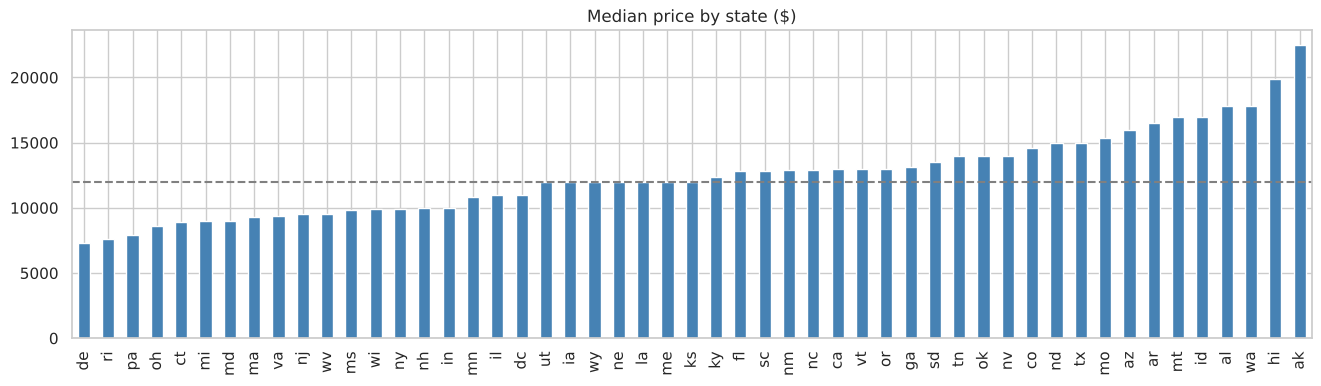

In [17]:
state_med = df.groupby('state')['price'].agg(['count', 'median']).sort_values('median')
print('Cheapest states:'); print(state_med.head(3))
print('\nMost expensive states:'); print(state_med.tail(3))

plt.figure(figsize=(16, 4))
state_med['median'].plot(kind='bar', color='steelblue')
plt.axhline(overall_median, color='grey', ls='--')
plt.title('Median price by state ($)')
plt.xlabel('')
plt.show()

In [18]:
model_counts = df['model'].value_counts()
print('Distinct model spellings :', len(model_counts))
print('Spellings with < 10 rows :', (model_counts < 10).sum())
print('Rows covered by top 50   :', f"{model_counts.head(50).sum() / df['model'].notna().sum():.1%}")
print('Top 10:', model_counts.head(10).to_dict())
print('\nregion levels:', df['region'].nunique(), '| state levels:', df['state'].nunique())

Distinct model spellings : 24166
Spellings with < 10 rows : 21730
Rows covered by top 50   : 27.8%
Top 10: {'f-150': 4391, 'silverado 1500': 2876, '1500': 2378, 'accord': 2035, 'camry': 2031, 'silverado': 1913, 'civic': 1871, 'altima': 1691, 'escape': 1678, 'wrangler': 1601}

region levels: 404 | state levels: 51


- Prices differ by state, from about \$7,300–7,900 (DE, RI, PA) to \$17,800–22,500 (WA, HI, AK). That is partly the
  local mix of trucks vs sedans, not only location. `state` (51 levels) will be one-hot encoded;
  `region` (404 levels, nested inside states) adds little and would create hundreds of columns → drop.
- `model` is free text with **24,166 spellings**; 21,730 of them appear fewer than 10 times, and the top 50 cover
  only 27.8% of rows. One-hot encoding it is not practical. Plan: keep `manufacturer` + `type` + `cylinders` +
  `drive`, and test grouping the most common models (others → "other") as an extra feature.

## 7. Are there outliers?

In [19]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'low_fence': low, 'high_fence': high, 'outliers': ((s < low) | (s > high)).sum()})

out = pd.DataFrame({c: iqr_outliers(s) for c, s in
                    {'price': df['price'], 'log_price': df['log_price'],
                     'odometer': df['odometer'], 'car_age': df['car_age']}.items()}).T
out['outlier_%'] = (out['outliers'] / len(df) * 100).round(1)
out.round(1)

,low_fence,high_fence,outliers,outlier_%
price,-16755.0,45245.0,9500.0,4.2
log_price,6.9,11.8,931.0,0.4
odometer,-79850.0,286654.0,1923.0,0.9
car_age,-8.5,27.5,2127.0,0.9


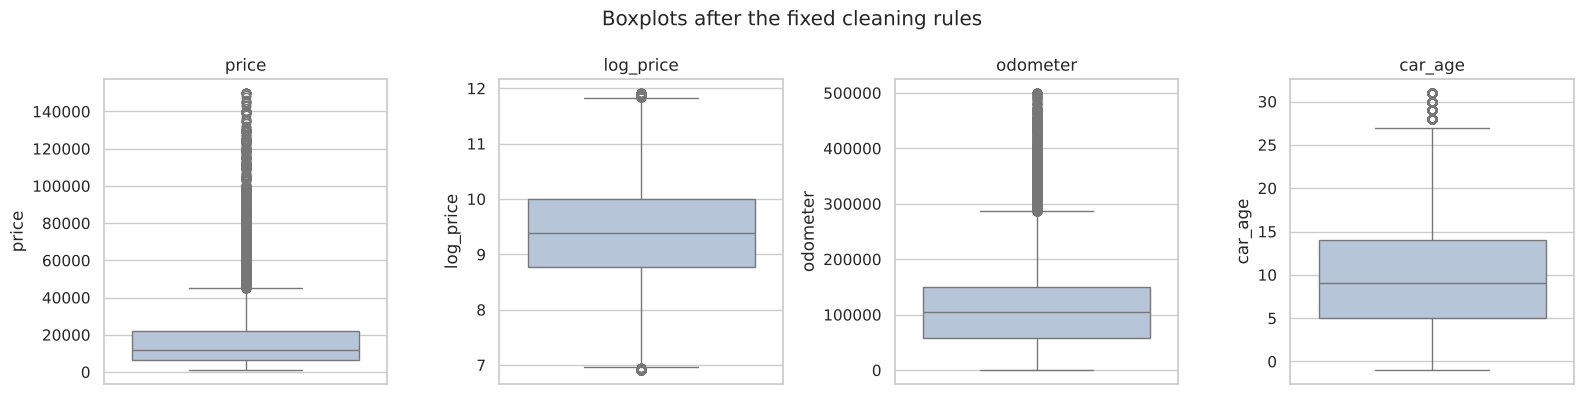

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['price', 'log_price', 'odometer', 'car_age']):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue')
    ax.set_title(col)
plt.suptitle('Boxplots after the fixed cleaning rules')
plt.tight_layout()
plt.show()

In [21]:
young = df['car_age'] > 1
print('odometer < 100 miles on cars older than 1 year:', ((df['odometer'] < 100) & young).sum())
print('odometer < 100 miles on cars 0-1 years old   :', ((df['odometer'] < 100) & ~young).sum())
print('Coordinates outside the US (lat 18-72, long -170 to -65):',
      ((df['lat'] < 18) | (df['lat'] > 72) | (df['long'] < -170) | (df['long'] > -65)).sum())

odometer < 100 miles on cars older than 1 year: 1832
odometer < 100 miles on cars 0-1 years old   : 719
Coordinates outside the US (lat 18-72, long -170 to -65): 80


- **`price`**: 9,500 rows (4.2%) are above the IQR fence of about \$45,245. These are real cars (newer pickups,
  luxury makes), not errors, so they are **kept**. On the log scale only 931 (0.4%) are outliers, which is another
  reason to model `log(price)`. MAE is reported next to RMSE because it is less sensitive to these values (lesson 05).
- **`odometer`**: 1,923 rows above about 286,654 miles: high but possible (work trucks); kept, and the skew is handled
  by a transform. The real problem is the **low end**: odometers under 100 miles on cars older than one year are
  placeholders → set to missing and impute the median inside the pipeline.
- **`car_age`**: 2,127 cars older than about 27 years: valid, already limited by the 1990 scope.
- **`lat`/`long`**: 80 rows outside the US, typing errors; not used as features, since `state` covers location.

## 8. EDA summary

| Finding | Number | What it means for modeling |
| --- | --- | --- |
| Reposted cars | 158,258 rows (37% of raw) | Removed before splitting → no copies of one car in train and test |
| Clean dataset | 225,703 rows × 18 features | Well above the 15k × 10 requirement |
| Target | continuous, skew 2.07 → −0.22 after log | Regression; compare `price` vs `log(price)`; report MAE and RMSE in dollars |
| Car age | Spearman 0.70 | Strongest driver; curved → log target or binning |
| Odometer | Spearman −0.59 | Second driver; low-end placeholders → missing → median |
| year vs car_age | r = −1 | Keep only `car_age` |
| age vs odometer | 0.65 (Spearman) | Below 0.8: keep both; Ridge for stability |
| Informative missingness | `condition` missing: \$14,998 vs \$10,000 median | "unknown" category, not mode imputation |
| `size` | 64.2% missing | Drop |
| Ordinal features | condition, cylinders | Ordinal encoding |
| `model` | 24,166 spellings | Not one-hot; top models + "other" as a test |
| `region` | 404 levels inside 51 states | Drop; keep `state` |
| Price outliers | 4.2% (IQR), 0.4% on log scale | Real cars: keep; log target + MAE |
| Old cars | prices rise before 1990 | Scope: model years 1990+ |